# Project 10: Overfitting and Underfitting Analysis


## Objective
To train neural network models of different complexity on the Iris dataset, compare their training and testing performance, and identify underfitting, suitable fitting, and overfitting.

## Introduction
A model **underfits** when it is too simple to learn the patterns in the data. A model is **appropriately fitted** when it learns useful patterns and performs well on unseen data. A model **overfits** when it learns the training data too closely and performs noticeably worse on unseen data.

In this experiment, all models use the same Iris dataset and the same train-test split. A small neural network is compared with medium and larger networks. The results help show how model complexity can affect generalization.

In [3]:
# Import libraries and load the Iris dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report

iris = load_iris()
X = iris.data
y = iris.target

print("Features:", iris.feature_names)
print("Classes:", iris.target_names)
print("Total samples:", len(X))

Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']
Total samples: 150


## Task 1: Prepare data and create different architectures

The Iris dataset contains 150 samples, four numeric features, and three flower classes. The dataset is split once so that every model uses exactly the same training and testing data. Feature scaling is fitted on the training data only.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 105
Testing samples: 45


We compare three neural network architectures:
- **Small:** one hidden layer with 4 neurons.
- **Medium:** one hidden layer with 16 neurons.
- **Large:** two hidden layers with 100 neurons each.

These are candidate examples. The actual training and testing scores will determine whether a model appears to underfit or overfit.

In [5]:
architectures = {
    "Small (4 neurons)": (4,),
    "Medium (16 neurons)": (16,),
    "Large (100, 100 neurons)": (100, 100)
}

models = {}
results = []

for name, layers in architectures.items():
    model = MLPClassifier(
        hidden_layer_sizes=layers,
        activation="relu",
        solver="adam",
        max_iter=2000,
        random_state=42
    )
    model.fit(X_train_scaled, y_train)
    models[name] = model

    train_accuracy = accuracy_score(y_train, model.predict(X_train_scaled))
    test_accuracy = accuracy_score(y_test, model.predict(X_test_scaled))

    results.append({
        "Model": name,
        "Architecture": str(layers),
        "Training accuracy": train_accuracy,
        "Testing accuracy": test_accuracy,
        "Generalization gap": train_accuracy - test_accuracy
    })

results_df = pd.DataFrame(results)
results_df.round(3)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,Architecture,Training accuracy,Testing accuracy,Generalization gap
0,Small (4 neurons),"(4,)",0.990,0.911,0.079
1,Medium (16 neurons),"(16,)",0.971,0.911,0.060
2,"Large (100, 100 neurons)","(100, 100)",1.000,0.933,0.067


## Task 2: Compare training and testing performance

The table compares the accuracy of each model on the training set and the unseen test set. A low score on both sets can suggest underfitting. High training accuracy with notably lower testing accuracy can suggest overfitting. High testing accuracy with a small gap suggests good generalization.

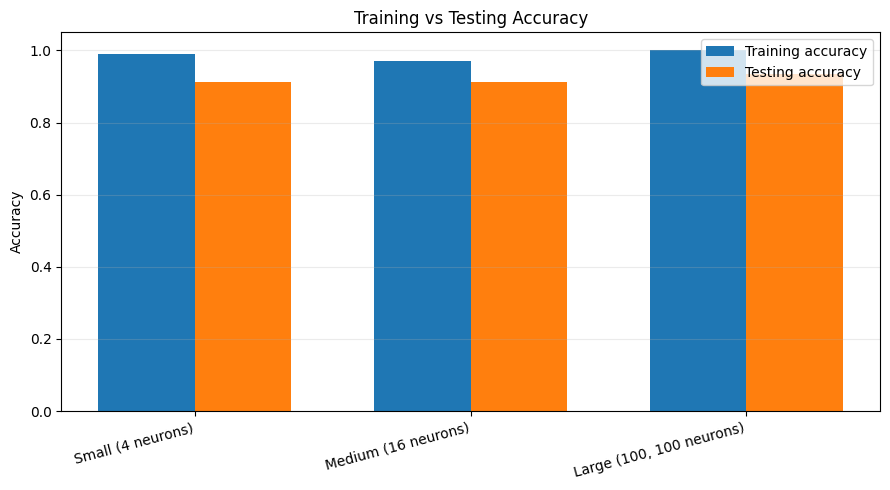

In [6]:
positions = np.arange(len(results_df))
bar_width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(positions - bar_width / 2, results_df["Training accuracy"],
        bar_width, label="Training accuracy")
plt.bar(positions + bar_width / 2, results_df["Testing accuracy"],
        bar_width, label="Testing accuracy")
plt.xticks(positions, results_df["Model"], rotation=15, ha="right")
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("Training vs Testing Accuracy")
plt.legend()
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Task 3: Identify fitting behaviour and possible improvements

The following rule gives a basic interpretation of the measured scores. These thresholds are only classroom guidelines; they are not universal definitions.

In [7]:
def interpret_model(row, low_score=0.85, gap_limit=0.10):
    train_score = row["Training accuracy"]
    test_score = row["Testing accuracy"]
    gap = row["Generalization gap"]

    if train_score < low_score and test_score < low_score:
        return "Possible underfitting"
    if gap > gap_limit and train_score > test_score:
        return "Possible overfitting"
    if test_score >= low_score and abs(gap) <= gap_limit:
        return "Reasonably fitted / good generalization"
    return "Mixed result; inspect scores and validate further"

results_df["Interpretation"] = results_df.apply(interpret_model, axis=1)
results_df.round(3)

,Model,Architecture,Training accuracy,Testing accuracy,Generalization gap,Interpretation
0,Small (4 neurons),"(4,)",0.990,0.911,0.079,Reasonably fitted / good generalization
1,Medium (16 neurons),"(16,)",0.971,0.911,0.060,Reasonably fitted / good generalization
2,"Large (100, 100 neurons)","(100, 100)",1.000,0.933,0.067,Reasonably fitted / good generalization


### Methods to improve performance

- **Underfitting:** increase model capacity, train for more iterations, or improve the input features.
- **Overfitting:** reduce network size, use regularization, gather more data, or use cross-validation.
- **Unstable results:** evaluate with cross-validation and compare average performance.

A model should be judged using both training and testing performance, not architecture size alone.

In [8]:
# Test-set classification reports for each model
for name, model in models.items():
    print("\\n" + "=" * 55)
    print(name)
    print(classification_report(
        y_test,
        model.predict(X_test_scaled),
        target_names=iris.target_names,
        zero_division=0
    ))

\n=======================================================
Small (4 neurons)
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45

\n=======================================================
Medium (16 neurons)
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45

\n=======================================================
Large (100, 100 neurons)
 

## Expected Output / Result

The Iris dataset is divided into training and testing sets, and three neural network architectures are trained using the same split. Their training and testing accuracies are compared in a table and bar chart. These results are used to identify possible underfitting, appropriate fitting, or overfitting. The experiment demonstrates that model complexity can affect how well a neural network performs on unseen data.

## Conclusion

This project compares neural networks of different sizes on the Iris classification task. Comparing training accuracy with testing accuracy helps identify whether a model may be too simple, generalizes well, or is overfitting. Adjusting model complexity, using regularization, and applying cross-validation are useful ways to improve performance.